# Experimental Crystal-Plasticity Descriptors

Implementation companion to the supplied Ti-5Al-2.5Sn manuscript. This notebook distinguishes **imported experimental information**, **derived descriptors**, and **inferred evidence classes**.

| Descriptor family | Data used here | Status |
| --- | --- | --- |
| Orientation, IPF, family orientation factors | Actual MPIE Ti-alloy GF2 grain averages | Experimental inputs, derived outputs |
| Geometrical/resistance-weighted competition | Actual orientations; declared CRSS ratios | Geometry plus sensitivity analysis, not fitted CRSS |
| Grain-boundary geometry and transfer | Actual GF2/RB exports | Derived m-prime, signed N, residual vectors, same-phase disorientation |
| Unloading/mechanical descriptors | Explicitly synthetic unloading curve | Demonstration, not measurements from the manuscript |
| AFM morphology | MI Ti-5Al-2.5Sn grain 176 / test B18 height scan | Experimental height; exploratory derived morphology, no registered trace comparison |
| Statistics/ordinal evidence classes | Explicitly synthetic labeled records | Demonstration only, not probabilities of slip activation |
| Provenance/export | Source hashes, conventions, methods, units, validity | Portable tables and JSON sidecars |
| Optional Granta MI bridge | Explicit local authentication and reviewed schema mapping | Read-only connection first; new-record upload off by default |

**Data limitation:** the repository exports do not contain the manuscript's matched 23 AFM/indentation records, 36-orientation selection, or 544-indent campaign. The 429 alpha grain averages below are not that selected cohort. No missing measurements, class labels, fits, or paper coefficients are invented.

## 1. Environment and Conventions

Install `python/requirements.txt` in the selected kernel if needed, or `python/requirements-granta.txt` for the optional Granta SDK. Bunge angles are in degrees; `g` maps sample to crystal and `g.T` maps crystal to sample. Unit normals/directions are used throughout. HCP lattice parameters below are the manuscript's declared values, not newly measured values. Connection secrets must be entered only in the local masked prompt, never placed in notebook source.

In [3]:
%matplotlib inline

from pathlib import Path
from importlib import reload
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import mannwhitneyu

python_dir = next(
    (candidate.resolve() for candidate in (Path.cwd(), Path.cwd() / "python")
     if (candidate / "experimental_descriptors.py").is_file()), None,
)
if python_dir is None:
    raise FileNotFoundError("Open this notebook from the repository root or its python folder.")
if str(python_dir) not in sys.path:
    sys.path.insert(0, str(python_dir))

import experimental_descriptors as descriptors
reload(descriptors)
from ebsd_mprime import read_tsl_reconstruction, reconstructed_mprime, slip_systems

data_dir = python_dir.parent / "gui_ebsd_map" / "ebsd_dataExamples"
grain_path = data_dir / "MPIE_Ti_alloy_GF2_RDdownTDright.txt"
boundary_path = data_dir / "MPIE_Ti_alloy_RB_RDdownTDright.txt"
scan = read_tsl_reconstruction(grain_path, boundary_path)
a_nm, c_nm = 0.298, 0.471
hcp_families = descriptors.hcp_slip_families(c_over_a=c_nm / a_nm)
print(f"Method: {descriptors.METHOD_VERSION}")
print(f"Experimental source: {len(scan.grain_ids)} grain averages, {len(scan.segments)} boundary segments")
print("HCP slip-system counts:", {name: len(systems[0]) for name, systems in hcp_families.items()})
print("BCC slip-system counts:", {name: len(systems[0]) for name, systems in descriptors.cubic_slip_families().items()})

Method: experimental-descriptors-1.0
Experimental source: 430 grain averages, 2813 boundary segments
HCP slip-system counts: {'basal': 3, 'prism1': 3, 'prism2': 3, 'pyram1_a': 6, 'pyram1_ca': 12, 'pyram2_ca': 6}
BCC slip-system counts: {'bcc110': 12, 'bcc112': 12, 'bcc123': 24}


## 2. Real Grain Orientations, Family Factors, and Competition

For the Bunge convention in the manuscript, the indentation axis in the crystal frame is

$$\mathbf{l}^{c}=g\mathbf{e}_Z=(\sin\phi_2\sin\Phi,\;\cos\phi_2\sin\Phi,\;\cos\Phi).$$

Each family uses $M_s=\max_{\alpha\in s}|\mathbf{l}^{c}\cdot\mathbf{n}_\alpha|\,|\mathbf{l}^{c}\cdot\mathbf{d}_\alpha|$. These factors are **geometrical descriptors, not indentation resolved shear stresses**. All six HCP slip families (33 systems) are available, with $c/a=0.471/0.298$ for the pyramidal conversions. Twinning is excluded because polarity is not handled by this absolute-value formulation.

The primary index is $\eta_{\mathrm{BP}}=(M_P-M_B)/(M_P+M_B+\varepsilon)$. It is marked undefined if both factors vanish; zero driving force is not evidence for a mixed mechanism. The HCP stereographic IPF sector uses antipodal directions, the positive c hemisphere, and basal azimuth 0-30 degrees. Coordinates are displayed, not converted into standard IPF RGB colors.

These are all alpha grains in the available export, **not the manuscript's selected 36 orientations or 23 complete records**. The spatial plot fills regions polygonized from the exported RB boundary segments and draws the measured segments in black (RD down, TD right). The outer rectangular perimeter is inferred from segment extrema. Grain identities come from RB adjacency, not nearest centers; a GF2 grain without an RB region cannot be colored and is reported. Gray means a non-alpha, undefined, or unassigned region.

Alpha grains: 429 | Defined competition indices: 429


,grain_id,c_axis_angle_deg,M_basal,M_prism1,M_pyram1_ca,eta_BP,eta_valid
0,2,86.347,0.060309,0.494322,0.463025,0.782526,True
1,3,34.664,0.432417,0.156336,0.458085,-0.468925,True
2,4,85.711,0.072770,0.495517,0.466031,0.743896,True
3,5,13.972,0.223213,0.029019,0.487781,-0.769901,True
4,6,48.563,0.485458,0.279380,0.351006,-0.269440,True


Grains with no assigned boundary region: [425]
Unresolved regions (gray): 1


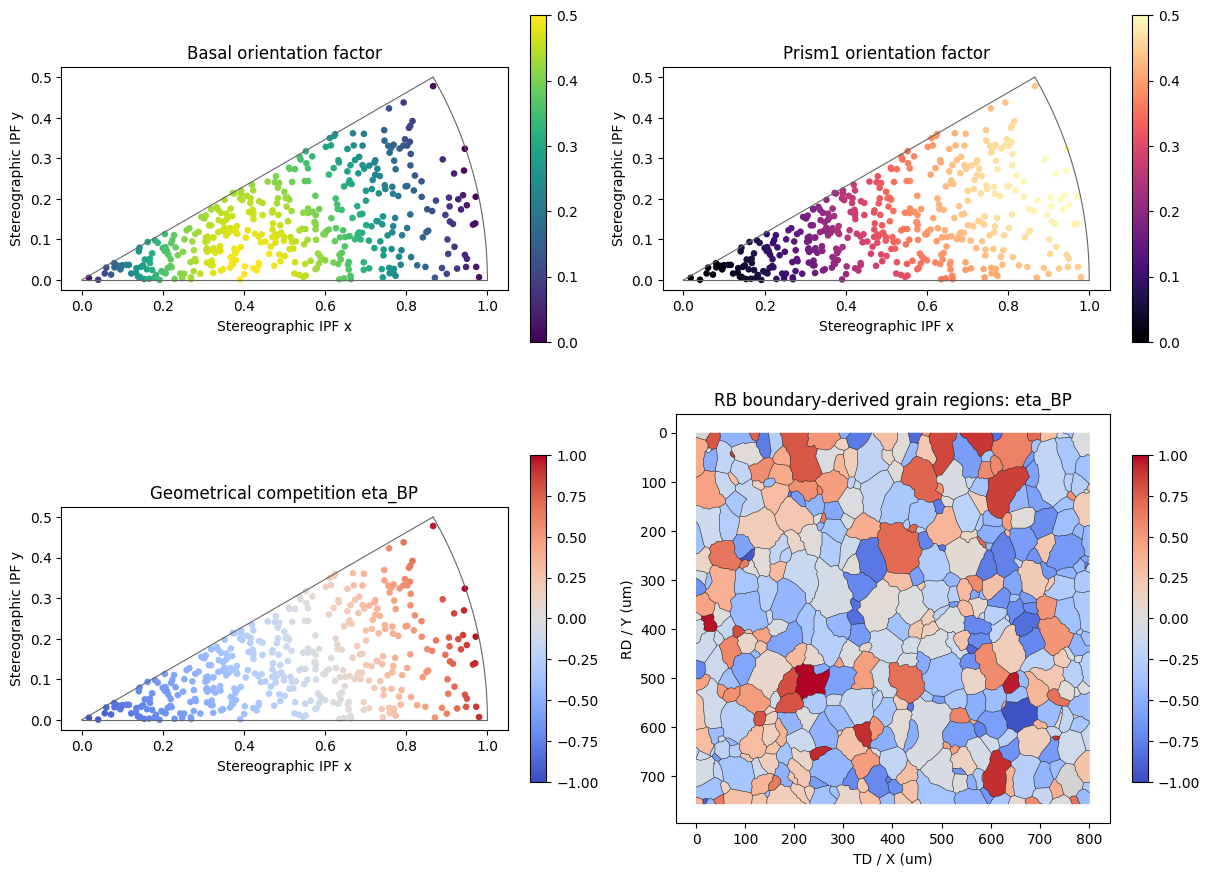

In [4]:
alpha_mask = scan.phases == 1
alpha_eulers = scan.eulers[alpha_mask]
orientation = descriptors.orientation_descriptors(alpha_eulers, structure="hcp")
factors = descriptors.family_orientation_factors(alpha_eulers, hcp_families)
M_B = factors["basal"]["maximum"]
M_P = factors["prism1"]["maximum"]
eta_BP, eta_valid = descriptors.competition_index(M_P, M_B)

grain_table = pd.DataFrame({
    "grain_id": scan.grain_ids[alpha_mask], "phase": 1,
    "phi1_deg": alpha_eulers[:, 0], "Phi_deg": alpha_eulers[:, 1], "phi2_deg": alpha_eulers[:, 2],
    "x_um": scan.centers[alpha_mask, 0], "y_um": scan.centers[alpha_mask, 1],
    "c_axis_angle_deg": orientation["c_axis_angle_deg"],
    "ipf_x": orientation["ipf_xy"][:, 0], "ipf_y": orientation["ipf_xy"][:, 1],
    "eta_BP": eta_BP, "eta_valid": eta_valid,
    "source_role": "experimental_grain_average", "information_level": "derived",
})
for family_name, result in factors.items():
    grain_table[f"M_{family_name}"] = result["maximum"]
    grain_table[f"argmax_{family_name}_zero_based"] = result["maximizing_system"]
for index, component in enumerate(("qx", "qy", "qz", "qw")):
    grain_table[component] = orientation["quaternion_xyzw"][:, index]

print(f"Alpha grains: {len(grain_table)} | Defined competition indices: {eta_valid.sum()}")
display(grain_table[["grain_id", "c_axis_angle_deg", "M_basal", "M_prism1", "M_pyram1_ca", "eta_BP", "eta_valid"]].head())

orientation_figure, orientation_axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
sector = np.linspace(0, np.pi / 6, 100)
for axes, values, title, cmap, limits in zip(
    orientation_axes.flat[:3], (M_B, M_P, eta_BP),
    ("Basal orientation factor", "Prism1 orientation factor", "Geometrical competition eta_BP"),
    ("viridis", "magma", "coolwarm"), ((0, 0.5), (0, 0.5), (-1, 1)),
):
    axes.plot([0, 1], [0, 0], color="0.4", linewidth=0.8)
    axes.plot([0, np.cos(np.pi / 6)], [0, np.sin(np.pi / 6)], color="0.4", linewidth=0.8)
    axes.plot(np.cos(sector), np.sin(sector), color="0.4", linewidth=0.8)
    plotted = axes.scatter(grain_table.ipf_x, grain_table.ipf_y, c=values, s=14,
                           cmap=cmap, vmin=limits[0], vmax=limits[1], rasterized=True)
    axes.set(title=title, xlabel="Stereographic IPF x", ylabel="Stereographic IPF y", aspect="equal")
    orientation_figure.colorbar(plotted, ax=axes, shrink=0.8)
from ebsd_mprime import plot_grain_tessellation
spatial_values = np.full(len(scan.grain_ids), np.nan)
spatial_values[alpha_mask] = eta_BP
spatial_axes = orientation_axes[1, 1]
spatial, missing_grains, unresolved_regions = plot_grain_tessellation(spatial_axes, scan, spatial_values)
spatial_axes.set_title("RB boundary-derived grain regions: eta_BP")
orientation_figure.colorbar(spatial, ax=spatial_axes, shrink=0.8)
print("Grains with no assigned boundary region:", missing_grains.tolist())
print("Unresolved regions (gray):", unresolved_regions)
plt.show()

## Example: Maximum m-prime on an EBSD boundary map

For each unique neighboring grain pair, the maximum Luster-Morris m-prime is
$$m'_{AB}=\max_{i,j}\left| (\mathbf{n}_{A,i}\cdot\mathbf{n}_{B,j})(\mathbf{d}_{A,i}\cdot\mathbf{d}_{B,j}) \right|,$$
where the slip-plane normals and directions are rotated into the sample frame. The GF2 file provides grain-average orientations and phases; the RB file provides the measured boundary segments and their grain-pair IDs. `reconstructed_mprime` calculates one value per unique pair using the HCP alpha and BCC beta slip systems, and every segment belonging to that pair is colored by that same value.

The map leaves grain interiors unfilled: these exports do not contain raw EBSD pixels or grain polygons. The small phase-colored markers show grain-center locations only; the viridis color scale applies to the boundary lines. Maximum m-prime is a geometric compatibility measure, not a prediction of which slip system activates or transfers across a boundary.

Computed 1196 unique grain-pair values; range = 0.622 to 0.999


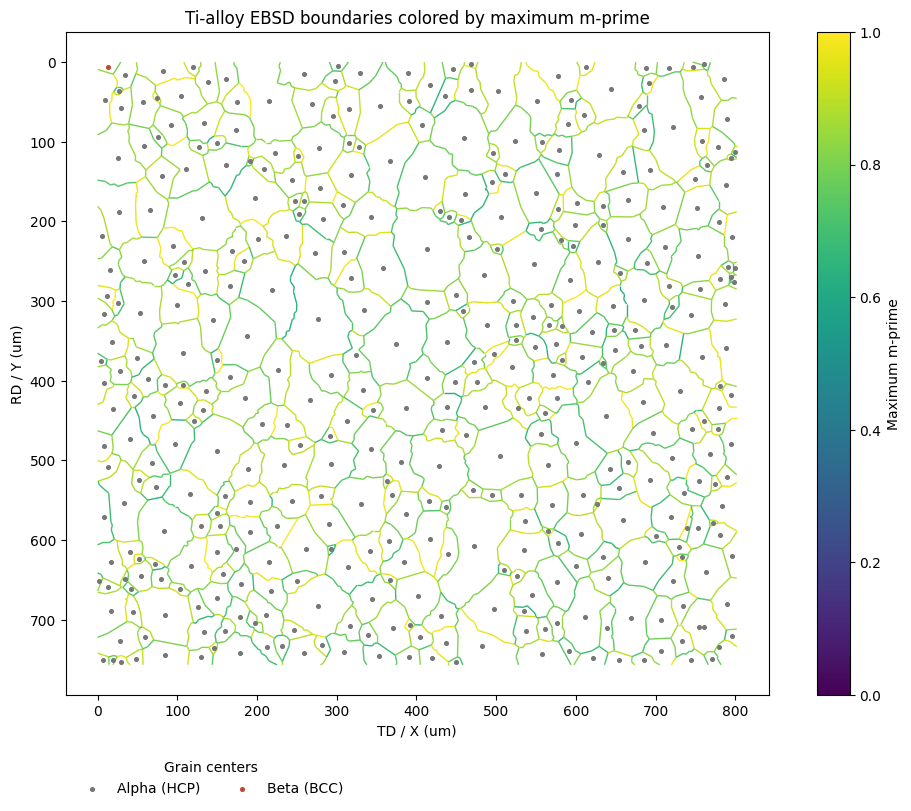

In [5]:
from ebsd_mprime import plot_reconstructed_map

mprime_values = reconstructed_mprime(scan)
print(
    f"Computed {len(mprime_values)} unique grain-pair values; "
    f"range = {mprime_values.min():.3f} to {mprime_values.max():.3f}"
)
mprime_figure = plot_reconstructed_map(
    scan, mprime_values, title="Ti-alloy EBSD boundaries colored by maximum m-prime"
)
plt.show()

## 3. CRSS Sensitivity and Real Grain-Boundary Descriptors

For sensitivity analysis only, $D_s=M_s/\tau_s$ and $\eta^{\tau}_{BP}=\log[(D_P+\varepsilon)/(D_B+\varepsilon)]$. The implementation scales both driving-force terms by a common CRSS scale before adding a dimensionless epsilon, preserving invariance to MPa versus Pa. Ratios 0.5, 1, and 2 below are **illustrative assumptions**, not identified Ti-alloy strengths.

The boundary table uses the **same basal+Prism1 HCP and BCC {110} sets as the earlier m-prime notebook** so its results remain comparable. The 33-system HCP factors above do not silently change this boundary definition. The signed Livingston-Chalmers matrix follows `N_factor.m`; `max_abs_N` is explicitly its largest absolute magnitude. Residual Burgers-vector norms use $\min(\|b_A-b_B\|,\|b_A+b_B\|)$ for bidirectional slip. The minimum over pairs need not occur at the m-prime-maximizing pair.

For alpha-alpha boundaries only, the declared `<a>` Burgers magnitude is $a=0.298$ nm. Beta/interphase residuals are left undefined because a beta lattice parameter was not supplied. Disorientation is calculated only for same-phase neighbors, with the appropriate symmetry. **A 2D boundary trace does not determine the 3D boundary inclination**, which stays undefined here.

,grain_A,grain_B,phase_A,phase_B,length_um,misorientation_deg,max_mprime,max_abs_N,min_residual_burgers_nm,residual_at_max_mprime_nm,boundary_inclination_deg
0,1,2,2,1,17.860,NaN,0.789600,0.771671,NaN,NaN,NaN
1,1,28,2,1,20.516,NaN,0.838440,0.853941,NaN,NaN,NaN
2,2,3,1,1,15.085,64.416856,0.856054,0.854137,0.079893,0.079893,NaN
3,2,28,1,1,17.863,12.924828,0.972534,0.968090,0.054286,0.054286,NaN
4,2,32,1,1,17.727,42.406282,0.752117,0.824730,0.123581,0.123581,NaN


Undefined 3D inclinations: 1196
Undefined interphase Burgers residuals: 2


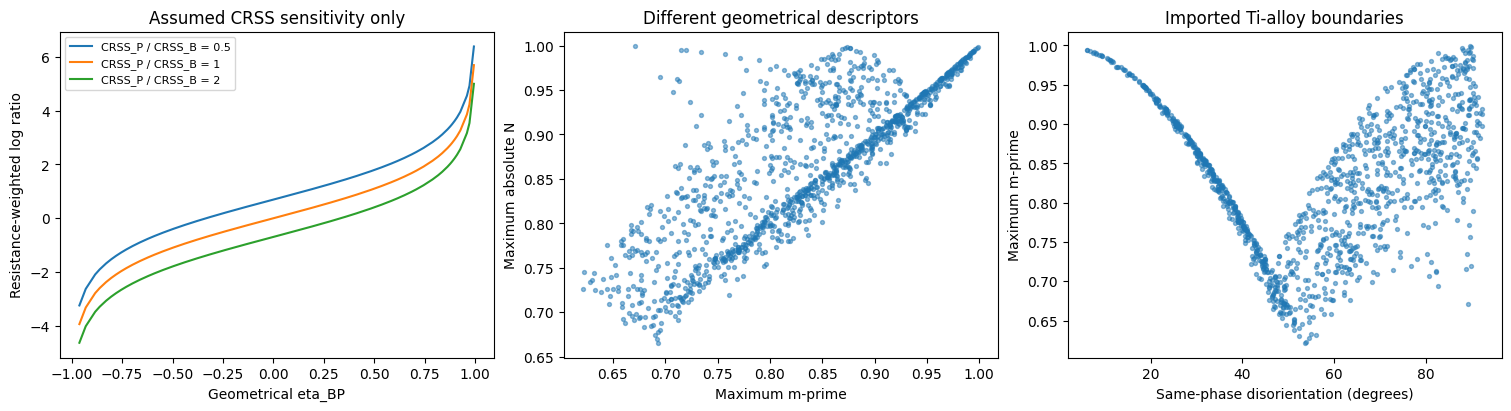

In [6]:
boundary_rows = []
phase_systems = {1: slip_systems("hcp"), 2: slip_systems("bcc")}
pair_lengths = np.bincount(scan.segment_pairs, weights=scan.boundary_lengths, minlength=len(scan.pairs))
for pair_index, (first, second) in enumerate(scan.pairs):
    phase_a, phase_b = int(scan.phases[first]), int(scan.phases[second])
    both_alpha = phase_a == phase_b == 1
    pair_result = descriptors.slip_pair_descriptors(
        scan.eulers[first], scan.eulers[second], phase_systems[phase_a], phase_systems[phase_b],
        burgers_a_nm=a_nm if both_alpha else None, burgers_b_nm=a_nm if both_alpha else None,
    )
    disorientation = np.nan
    if phase_a == phase_b:
        disorientation = float(descriptors.same_phase_misorientation(
            [scan.eulers[first]], [scan.eulers[second]], "hcp" if both_alpha else "bcc",
        )[0])
    boundary_rows.append({
        "grain_A": int(scan.grain_ids[first]), "grain_B": int(scan.grain_ids[second]),
        "phase_A": phase_a, "phase_B": phase_b, "length_um": pair_lengths[pair_index],
        "misorientation_deg": disorientation,
        **{key: pair_result[key] for key in ("max_mprime", "max_abs_N", "min_residual_burgers_nm",
                                           "residual_at_max_mprime_nm", "boundary_inclination_deg")},
    })
boundary_table = pd.DataFrame(boundary_rows)
np.testing.assert_allclose(boundary_table.max_mprime, reconstructed_mprime(scan), atol=1e-14)
display(boundary_table.head())
print("Undefined 3D inclinations:", boundary_table.boundary_inclination_deg.isna().sum())
print("Undefined interphase Burgers residuals:", boundary_table.min_residual_burgers_nm.isna().sum())

sensitivity_figure, sensitivity_axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ratio in (0.5, 1.0, 2.0):
    weighted_eta = descriptors.resistance_competition(M_P, M_B, crss_first=ratio, crss_second=1)
    order = np.argsort(eta_BP)
    sensitivity_axes[0].plot(eta_BP[order], weighted_eta[order], label=f"CRSS_P / CRSS_B = {ratio:g}")
sensitivity_axes[0].set(xlabel="Geometrical eta_BP", ylabel="Resistance-weighted log ratio", title="Assumed CRSS sensitivity only")
sensitivity_axes[0].legend(fontsize=8)
sensitivity_axes[1].scatter(boundary_table.max_mprime, boundary_table.max_abs_N, s=8, alpha=0.5)
sensitivity_axes[1].set(xlabel="Maximum m-prime", ylabel="Maximum absolute N", title="Different geometrical descriptors")
sensitivity_axes[2].scatter(boundary_table.misorientation_deg, boundary_table.max_mprime, s=8, alpha=0.5)
sensitivity_axes[2].set(xlabel="Same-phase disorientation (degrees)", ylabel="Maximum m-prime", title="Imported Ti-alloy boundaries")
plt.show()

### Separate maps for N-factor and residual Burgers-vector metrics

The m-prime boundary map is shown above. Here, `max_abs_N` is the maximum absolute value in the Livingston–Chalmers N matrix. `max_signed_N` is the signed N-matrix entry whose absolute value is largest, so the diverging color scale retains its sign. The residual maps show the minimum residual Burgers magnitude and the residual for the slip pair that maximizes m-prime. Residuals are computed only for alpha-alpha boundaries because a beta Burgers magnitude is not supplied; undefined values are masked rather than shown as zero.

In [ ]:
import ebsd_mprime
from importlib import reload as reload_module
reload_module(ebsd_mprime)

signed_n_values = np.empty(len(scan.pairs))
for pair_index, (first, second) in enumerate(scan.pairs):
    phase_a, phase_b = int(scan.phases[first]), int(scan.phases[second])
    n_matrix = descriptors.slip_pair_descriptors(
        scan.eulers[first], scan.eulers[second], phase_systems[phase_a], phase_systems[phase_b],
    )["N_signed_matrix"]
    signed_n_values[pair_index] = n_matrix.flat[np.abs(n_matrix).argmax()]
boundary_table["max_signed_N"] = signed_n_values
display(boundary_table[[
    "grain_A", "grain_B", "max_abs_N", "max_signed_N",
    "min_residual_burgers_nm", "residual_at_max_mprime_nm",
]].head())

metric_map_specs = (
    ("max_abs_N", "Maximum absolute Livingston-Chalmers N", "Maximum |N|", "viridis", 0, 1),
    ("max_signed_N", "Signed Livingston-Chalmers N at maximum |N|", "Signed N factor", "coolwarm", -1, 1),
    ("min_residual_burgers_nm", "Minimum residual Burgers-vector magnitude", "Residual Burgers vector (nm)", "viridis", 0, a_nm),
    ("residual_at_max_mprime_nm", "Residual Burgers vector at maximum m-prime", "Residual Burgers vector (nm)", "viridis", 0, a_nm),
)
for column, title, colorbar_label, cmap, vmin, vmax in metric_map_specs:
    metric_figure = ebsd_mprime.plot_reconstructed_map(
        scan, boundary_table[column].to_numpy(), title=title,
        cmap=cmap, vmin=vmin, vmax=vmax, colorbar_label=colorbar_label,
    )
    display(metric_figure)
    plt.close(metric_figure)

,grain_A,grain_B,max_abs_N,max_signed_N,min_residual_burgers_nm,residual_at_max_mprime_nm
0,1,2,0.771671,-0.771671,NaN,NaN
1,1,28,0.853941,-0.853941,NaN,NaN
2,2,3,0.854137,-0.854137,0.079893,0.079893
3,2,28,0.968090,-0.968090,0.054286,0.054286
4,2,32,0.824730,-0.824730,0.123581,0.123581


## 4. Mechanical Descriptors Ã¢â‚¬â€ Synthetic Unloading Demonstration

**No experimental indentation curve is loaded in this section.** The generated unloading segment is used only to demonstrate fitting $P=\alpha(h-h_f)^m$, then evaluating $S=\alpha m(h_{max}-h_f)^{m-1}$, $h_c=h_{max}-0.75P_{max}/S$, and conventional $H=P_{max}/A_c$.

Input units are **nm and mN**. The caller must pass the unloading segment, not a mixed loading/hold/unloading time series. The fit interval, residual-depth bounds, and exponent bounds (1.01 to 3) are explicit implementation choices, not a universal indentation law. Fit quality does not itself validate the contact model.

For this demonstration only, the area function is an ideal spherical geometry with nominal radius 1400 nm. **It is not a calibrated experimental tip-area function** and the displayed hardness is not a manuscript result. Without an area function, hardness is undefined. No pile-up correction or elastic modulus is inferred.

SYNTHETIC DEMONSTRATION Ã¢â‚¬â€ not experimental indentation results


,synthetic_value
pmax_mN,6.000609
hmax_nm,300.0
alpha_mN_nm_minus_m,0.001007
exponent_m,1.598649
hf_nm,70.173714
stiffness_mN_per_nm,0.041737
stiffness_N_per_m,41737.347567
contact_depth_nm,192.171943
contact_area_nm2,1574413.511655
hardness_GPa,3.81133


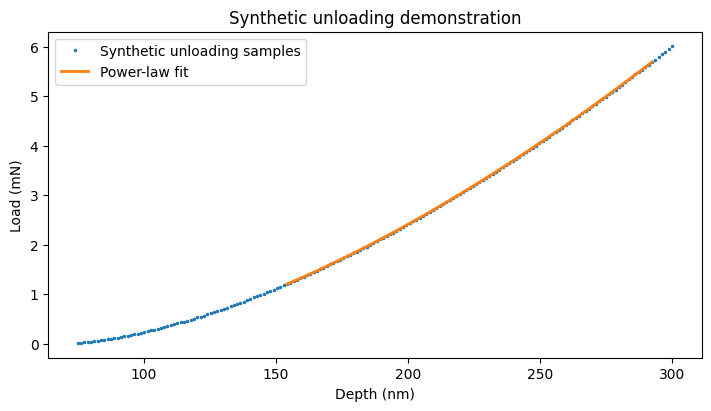

In [4]:
random = np.random.default_rng(42)
demo_depth_nm = np.linspace(300, 75, 180)
demo_alpha = 6 / (300 - 70)**1.6
demo_load_mN = demo_alpha * (demo_depth_nm - 70)**1.6
demo_load_mN = np.maximum(demo_load_mN + random.normal(0, 0.002, len(demo_load_mN)), 0)


def illustrative_sphere_area_nm2(contact_nm):
    radius_nm = 1400.0
    return np.pi * (2 * radius_nm * contact_nm - contact_nm**2)


mechanical_demo = descriptors.unloading_descriptors(
    demo_depth_nm, demo_load_mN, area_function_nm2=illustrative_sphere_area_nm2,
    fit_fraction=(0.2, 0.95),
)
mechanical_scalars = {key: value for key, value in mechanical_demo.items() if not isinstance(value, np.ndarray)}
print("SYNTHETIC DEMONSTRATION Ã¢â‚¬â€ not experimental indentation results")
display(pd.DataFrame([mechanical_scalars]).T.rename(columns={0: "synthetic_value"}))
mechanical_figure, mechanical_axes = plt.subplots(figsize=(7, 4), constrained_layout=True)
mechanical_axes.plot(demo_depth_nm, demo_load_mN, ".", markersize=3, label="Synthetic unloading samples")
mechanical_axes.plot(mechanical_demo["fit_depth_nm"], mechanical_demo["predicted_load_mN"], linewidth=2, label="Power-law fit")
mechanical_axes.set(title="Synthetic unloading demonstration", xlabel="Depth (nm)", ylabel="Load (mN)")
mechanical_axes.legend()
plt.show()

## 5. Experimental AFM Morphology from Granta MI

The input is `mercier_tialloy_b18.000`, the Height channel from the MI record `Ti5AlSn2.5Sn_AFM_2014-03-05`, linked to `Ti5Al2.5Sn_1_Gr176_TestB18`. It was extracted from `2014-03-05_AFM.7z`. Gwyddion's Nanoscope reader supplies physical units; this is a measured 512 x 512 height map, not a synthetic image. The raw file is kept locally in the ignored `python/mi_afm_data/` directory, not committed. If absent, retrieve the archive from the MI record and extract the named file there, or set `GRANTA_AFM_FILE` to its path. No fabricated fallback is used.

The impression center is initially the minimum-height pixel. The ROI, leveling annulus, and intensity annulus below are **exploratory choices** and require experimental review; the leveling annulus is assumed undeformed. The plot displays the selected annulus. Heights, areas, volumes, and angular intensities are therefore provisional derived descriptors, not paper coefficients. `R_h` remains undefined because a matching experimental maximum indentation depth has not been supplied; the synthetic unloading curve is not used.

Image Y increases downward in the displayed scan coordinates; the scan has not been registered to EBSD. No AFM-to-EBSD rotation, trace assignment, or physical slip mechanism is inferred. The record's displayed experiment date differs from the archive and scan header date; verify the metadata before publication.


Measured MI AFM scan: mercier_tialloy_b18.000 | SHA-256: b557c7ae684be138a4fbed3a85a468172be570e9df1b6d67320111144c217731
MI record: Ti5AlSn2.5Sn_AFM_2014-03-05 | linked grain: 176 / test B18
Exploratory minimum-pixel center (um): (4.794921874999994, 5.439453124999993) | scan size (pixels): (512, 512)
Provisional: review the center and undeformed leveling annulus before interpretation.


,h_PU_nm,R_h,A_PU_um2,V_PU_um3,roi_valid_fraction,roi_clipped_by_field
0,43.554091,NaN,29.195023,0.174033,1.0,False


Morphology Fourier amplitudes: {'2': 0.02992398449167421, '3': 0.10974133106294393, '6': 0.04050777016033886}


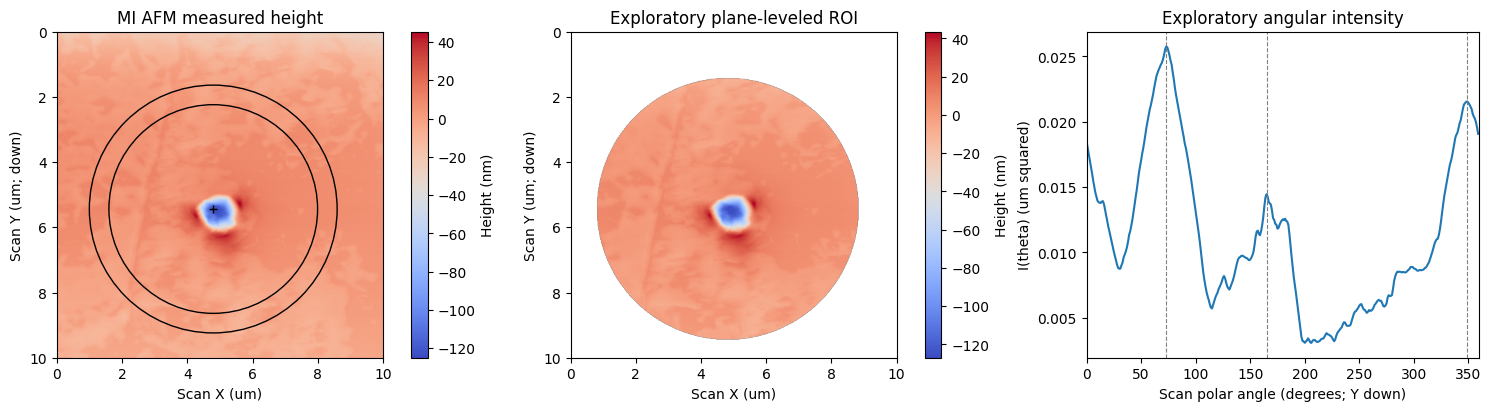

In [3]:
import os
from matplotlib.patches import Circle

afm_path = Path(os.environ.get(
    "GRANTA_AFM_FILE", str(python_dir / "mi_afm_data" / "mercier_tialloy_b18.000"),
))
afm_scan = descriptors.read_afm_height(afm_path)
x_um, y_um, height_nm = afm_scan["x_um"], afm_scan["y_um"], afm_scan["height_nm"]
minimum_row, minimum_column = np.unravel_index(np.nanargmin(height_nm), height_nm.shape)
center_um = (float(x_um[minimum_column]), float(y_um[minimum_row]))
radius_um = 4.0
level_annulus_um = (3.2, 3.8)
intensity_annulus_um = (0.7, 1.9)
afm_result = descriptors.afm_descriptors(
    x_um, y_um, height_nm, center_um=center_um, radius_um=radius_um,
    level_annulus_um=level_annulus_um, intensity_annulus_um=intensity_annulus_um,
    positive_threshold_nm=1.0, angle_samples=360,
)
print("Measured MI AFM scan:", afm_path.name, "| SHA-256:", afm_scan["source_sha256"])
print("MI record: Ti5AlSn2.5Sn_AFM_2014-03-05 | linked grain: 176 / test B18")
print("Exploratory minimum-pixel center (um):", center_um, "| scan size (pixels):", height_nm.shape)
print("Provisional: review the center and undeformed leveling annulus before interpretation.")
display(pd.DataFrame([{key: afm_result[key] for key in (
    "h_PU_nm", "R_h", "A_PU_um2", "V_PU_um3", "roi_valid_fraction", "roi_clipped_by_field",
)}]))
print("Morphology Fourier amplitudes:", afm_result["angular_symmetry_amplitudes"])

dx, dy = x_um[1] - x_um[0], y_um[1] - y_um[0]
extent = (x_um[0] - dx / 2, x_um[-1] + dx / 2, y_um[-1] + dy / 2, y_um[0] - dy / 2)
morphology_figure, morphology_axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for axes, height, title in zip(
    morphology_axes[:2], (height_nm, afm_result["height_levelled_nm"]),
    ("MI AFM measured height", "Exploratory plane-leveled ROI"),
):
    image = axes.imshow(height, extent=extent, origin="upper", cmap="coolwarm")
    axes.set(title=title, xlabel="Scan X (um)", ylabel="Scan Y (um; down)", aspect="equal")
    morphology_figure.colorbar(image, ax=axes, label="Height (nm)")
for radius in level_annulus_um:
    morphology_axes[0].add_patch(Circle(center_um, radius, fill=False, color="black", linewidth=1))
morphology_axes[0].plot(*center_um, marker="+", color="black")
morphology_axes[2].plot(afm_result["angles_deg"], afm_result["intensity_um2"])
for peak in afm_result["peak_angles_deg"]:
    morphology_axes[2].axvline(peak, color="0.5", linewidth=0.8, linestyle="--")
morphology_axes[2].set(title="Exploratory angular intensity", xlabel="Scan polar angle (degrees; Y down)",
                       ylabel="I(theta) (um squared)", xlim=(0, 360))
plt.show()


## 6. Association, Uncertainty, and Ordered Evidence Classes - Synthetic Demonstration

**No experimental class labels or fitted manuscript coefficients are available.** The following records, mechanical responses, and classes are generated solely to exercise the statistical APIs. The synthetic label-generation rule is known by construction and is not evidence for a Ti-alloy mechanism trend.

The proportional-odds model is the manuscript's form:

$$\log\frac{P(Y\leq k)}{P(Y>k)}=\alpha_k-\beta\eta_{BP},\qquad k=1,2.$$

A positive beta orders classifications toward prismatic-compatible evidence as eta increases. Classes are **basal-compatible, mixed, and prismatic-compatible**, not direct observations of dislocation activity. For real data they must be assigned from independent evidence, not by thresholding eta and then regressing those thresholds against eta.

The demonstration includes Spearman correlation with a grain-cluster percentile-bootstrap interval, an illustrative nonparametric group comparison, axial circular statistics for line angles, and ordinal regression with **leave-one-grain-out** validation. When every record is an independent grain, this reduces to leave-one-record-out. Failed folds remain visible as missing predictions. Class probabilities describe assignment uncertainty, not a constitutive probability of slip activation. Small-sample diagnostics and proportional-odds assumptions require separate scientific assessment before publication.

SYNTHETIC STATISTICS - do not use these coefficients as paper results
Class counts: {'Basal-compatible': np.int64(22), 'Mixed': np.int64(17), 'Prismatic-compatible': np.int64(21)}
Spearman association / grain bootstrap: {'spearman_rho': 0.6875243123089748, 'p_value': nan, 'p_value_note': 'not reported for clustered data', 'rho_ci_95': [0.41062244194949, 0.8399178663406212], 'paired_records': 60, 'bootstrap_resampling_unit': 'grain', 'bootstrap_resamples': 400, 'seed': 42}
Ordinal beta and 95% model interval: 1.1458317190444411 [0.2995151828879644, 1.992148255200918]
Interval assumption: model-based interval, not cluster-robust
Leave-one-grain-out valid fraction: 1.0
Failed validation folds: []
Independent-grain low/high-eta comparison (synthetic only): MannwhitneyuResult(statistic=np.float64(13.0), pvalue=np.float64(0.00579535854433471))
Axial line-angle example: {'mean_line_angle_deg': 0.0, 'resultant_length': 0.9984774386394599, 'circular_std_deg': 1.581468156320241, 'count': 4}


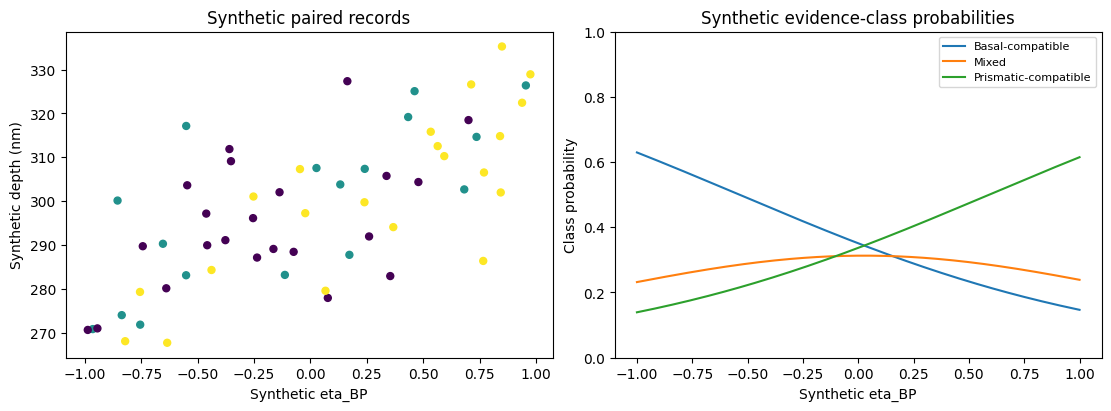

In [9]:
statistical_random = np.random.default_rng(2026)
demo_grain_ids = np.repeat(np.arange(20), 3)
demo_eta = np.repeat(np.linspace(-0.95, 0.95, 20), 3) + statistical_random.normal(0, 0.02, 60)
demo_response_nm = 300 + 18 * demo_eta + statistical_random.normal(0, 12, 60)
demo_latent = 1.5 * demo_eta + statistical_random.logistic(size=60)
demo_classes = np.digitize(demo_latent, [-0.6, 0.6])
class_names = ["Basal-compatible", "Mixed", "Prismatic-compatible"]

association_demo = descriptors.association_summary(
    demo_eta, demo_response_nm, n_resamples=400, seed=42, cluster_ids=demo_grain_ids,
)
ordinal_demo = descriptors.ordinal_evidence_model(
    demo_eta, demo_classes, leave_one_out=True, grain_ids=demo_grain_ids,
)
independent_grains_demo = pd.DataFrame({
    "grain_id": demo_grain_ids, "eta": demo_eta, "response_nm": demo_response_nm,
}).groupby("grain_id").mean()
rank_test_demo = mannwhitneyu(
    independent_grains_demo.loc[independent_grains_demo.eta < 0, "response_nm"],
    independent_grains_demo.loc[independent_grains_demo.eta >= 0, "response_nm"], alternative="two-sided",
)
print("SYNTHETIC STATISTICS - do not use these coefficients as paper results")
print("Class counts:", dict(zip(class_names, np.bincount(demo_classes, minlength=3))))
print("Spearman association / grain bootstrap:", association_demo)
print("Ordinal beta and 95% model interval:", ordinal_demo["beta"], ordinal_demo["beta_ci_95"])
print("Interval assumption:", ordinal_demo["beta_ci_note"])
print("Leave-one-grain-out valid fraction:", ordinal_demo["cross_validation"]["valid_fraction"])
print("Failed validation folds:", ordinal_demo["cross_validation"]["failed_folds"])
print("Independent-grain low/high-eta comparison (synthetic only):", rank_test_demo)
print("Axial line-angle example:", descriptors.axial_statistics([178, 179, 1, 2]))

statistical_figure, statistical_axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
statistical_axes[0].scatter(demo_eta, demo_response_nm, c=demo_classes, cmap="viridis", s=25)
statistical_axes[0].set(title="Synthetic paired records", xlabel="Synthetic eta_BP", ylabel="Synthetic depth (nm)")
eta_grid = np.linspace(-1, 1, 200)
probability_grid = ordinal_demo["fit"].model.predict(ordinal_demo["fit"].params, exog=eta_grid[:, None])
for class_index, class_name in enumerate(class_names):
    statistical_axes[1].plot(eta_grid, probability_grid[:, class_index], label=class_name)
statistical_axes[1].set(title="Synthetic evidence-class probabilities", xlabel="Synthetic eta_BP", ylabel="Class probability", ylim=(0, 1))
statistical_axes[1].legend(fontsize=8)
plt.show()

## 7. Provenance-Aware Export and Database Integration

The export below writes **only the real orientation/grain-boundary tables**, not the synthetic curves, AFM metrics, classes, or fitted coefficients. CSV missing values stay empty. A JSON sidecar records source-file SHA-256 hashes, processing date, method/software versions, conventions, lattice parameters, slip-family selections, units, validity definitions, and source/derived column distinctions.

Grain IDs and boundary grain-pair IDs remain those of the source exports. They can be used as join keys to externally maintained material/sample/orientation/indentation/AFM records. This notebook does not invent the missing indentation-to-grain or AFM-to-indent links or claim a CHADA/CHAMEO-compliant schema. Sections 8-9 provide an optional Granta MI connection and reviewed package-level upload, separate from descriptor calculation.

Files are written to `python/descriptor_exports` and can be regenerated. Preserve the source data and the manifest together when reusing the outputs. The two tables should not be pooled as independent measurements: one contains grain-level records, the other neighboring-grain pairs. Exporting these files alone makes no network requests or server changes.

In [12]:
reload(descriptors)


def descriptor_unit(column):
    if column.endswith("_nm"):
        return "nm"
    if column.endswith("_um"):
        return "um"
    if column.endswith("_deg"):
        return "degree"
    if column.endswith("_id") or column in ("grain_A", "grain_B", "source_role", "information_level"):
        return "identifier_or_metadata"
    return "1"


tables_to_export = {"grain_descriptors": grain_table, "boundary_descriptors": boundary_table}
column_units = {name: {column: descriptor_unit(column) for column in table.columns}
                for name, table in tables_to_export.items()}
manifest = descriptors.provenance_manifest(
    sources=[grain_path, boundary_path], dataset_role="experimental",
    parameters={
        "loading_axis_sample": [0, 0, 1], "epsilon": 1e-12,
        "hcp_a_nm": a_nm, "hcp_c_nm": c_nm, "lattice_parameter_source": "supplied manuscript, not measured here",
        "orientation_factor_families": list(hcp_families),
        "boundary_families": {"alpha": ["basal", "prism1"], "beta": ["bcc110"]},
        "maximizing_system_indexing": "zero-based within the named family",
        "matched_indent_afm_records_available": False,
    },
    units=column_units,
)
imported_columns = {"grain_id", "phase", "phi1_deg", "Phi_deg", "phi2_deg", "x_um", "y_um", "source_role"}
manifest["column_information_levels"] = {
    "grain_descriptors": {column: "imported_from_GF2" if column in imported_columns else "derived"
                          for column in grain_table.columns},
    "boundary_descriptors": {column: "source_identifier" if column in ("grain_A", "grain_B", "phase_A", "phase_B")
                             else "derived_from_GF2_RB" for column in boundary_table.columns},
}
manifest["join_keys"] = {"grain_descriptors": ["grain_id"], "boundary_descriptors": ["grain_A", "grain_B"]}
manifest["validity_definitions"] = {
    "eta_valid": "Both factors finite and their sum exceeds epsilon; invalid eta is missing, not mixed",
    "boundary_inclination_deg": "Missing because no 3D boundary normals were provided",
    "min_residual_burgers_nm": "Only alpha-alpha evaluated; beta Burgers magnitudes unavailable",
    "misorientation_deg": "Only same-phase disorientation evaluated",
    "classes": "No experimental mechanism labels exported",
    "cohort": "All alpha grains in this GF2 export, not the manuscript's selected indentation/AFM cohort",
}
export_paths = descriptors.export_descriptor_tables(python_dir / "descriptor_exports", tables_to_export, manifest)
for path in export_paths:
    print(path)
assert len(pd.read_csv(export_paths[0])) == 429
assert len(pd.read_csv(export_paths[1])) == 1196
assert json.loads(export_paths[2].read_text())["dataset_role"] == "experimental"
print("Export read-back verified: 429 grain rows, 1,196 boundary-pair rows, provenance sidecar.")

C:\github\stabix\python\descriptor_exports\grain_descriptors.csv
C:\github\stabix\python\descriptor_exports\boundary_descriptors.csv
C:\github\stabix\python\descriptor_exports\provenance.json
Export read-back verified: 429 grain rows, 1,196 boundary-pair rows, provenance sidecar.


## 8. Optional Granta MI Connection and Read-Only Schema Inspection

The bridge in `granta_mi_bridge.py` follows the supplied MIdata helpers, with SDK-version checks and non-destructive defaults. SDK 5 uses `ansys.grantami.core.SessionBuilder`; older SDKs can use the legacy `connect` API. Install `python/requirements-granta.txt` in the kernel if needed.

**Connection is off by default.** Set `ENABLE_MI_CONNECTION = True` below to connect. Settings can be supplied through `GRANTA_MI_SERVER`, `GRANTA_MI_DB_KEY`, `GRANTA_MI_TABLE`, `GRANTA_MI_AUTH`, and optionally `GRANTA_MI_USERNAME`. `GRANTA_MI_AUTH` is `sso` or `password`. In password mode, enter the password only into the local masked `getpass` prompt; it is not saved in this notebook, an environment file, logs, or the upload package. Do not copy the password literal from the supplied example notebook; rotate it if still active.

This cell only connects and inspects schema. It does not create, clear, or update records. An optional exact sample-record name allows function/tabular column-header inspection. `read_scalar` preserves missing values; `read_function_frame` returns function headers/ranges without guessing unit conversions or averaging ranges.

**Live verification status:** the implementation's SDK 5 read-only SSO probe received no usable Service Layer response from the supplied endpoint. Server/VPN/firewall/SSO requirements and table access therefore remain unverified. No password was used and no server records were changed.

In [10]:
import os
import getpass
import granta_mi_bridge as mi_bridge
reload(mi_bridge)

ENABLE_MI_CONNECTION = False
mi_config = mi_bridge.MIConfig(
    server_url=os.environ.get("GRANTA_MI_SERVER", "https://nanomecommons.grantami.com/mi_servicelayer"),
    database_key=os.environ.get("GRANTA_MI_DB_KEY", "MI_Blank_v2021"),
    table_name=os.environ.get("GRANTA_MI_TABLE", "Indentation test data"),
    timeout_ms=20000,
)
mi_authentication = os.environ.get("GRANTA_MI_AUTH", "sso")
MI_SAMPLE_RECORD_NAME = os.environ.get("GRANTA_MI_SAMPLE_RECORD", "")
mi_session = mi_database = mi_table = live_mi_schema = None

if ENABLE_MI_CONNECTION:
    try:
        if mi_authentication == "password":
            username_value = os.environ.get("GRANTA_MI_USERNAME") or input("Granta MI username: ")
            password_value = getpass.getpass("Granta MI password (not saved): ")
            try:
                mi_session, mi_database, mi_table = mi_bridge.connect_mi(
                    mi_config, authentication="password", username=username_value, password=password_value,
                )
            finally:
                del password_value
        else:
            mi_session, mi_database, mi_table = mi_bridge.connect_mi(mi_config, authentication=mi_authentication)
        sample_record = None
        if MI_SAMPLE_RECORD_NAME:
            candidates = mi_table.search_for_records_by_name(MI_SAMPLE_RECORD_NAME)
            if len(candidates) != 1:
                raise ValueError("The sample record name must identify exactly one record; no automatic first-match selection.")
            sample_record = candidates[0]
        live_mi_schema = mi_bridge.inspect_mi_schema(mi_table, sample_record=sample_record)
        print("Read-only connection succeeded. No records created or updated.")
        display(pd.DataFrame(live_mi_schema["attributes"].values())[["name", "type", "unit"]])
    except ConnectionError as error:
        mi_session = mi_database = mi_table = None
        print(str(error))
else:
    print("Granta MI network connection disabled. Set ENABLE_MI_CONNECTION = True to connect locally.")
    print("No password read, no network requests, no server writes in this run.")

Granta MI network connection disabled. Set ENABLE_MI_CONNECTION = True to connect locally.
No password read, no network requests, no server writes in this run.


## 9. Granta MI Descriptor Package, Mapping Preview, and Explicit Upload

This packages only the **real experimental-derived CSVs and provenance** from Section 7. It excludes synthetic indentation/AFM/statistical outputs, connection settings, usernames, and credentials. Units and original grain IDs remain in the CSV/JSON payload rather than being assigned to guessed MI fields.

The attached indentation schema has `Raw results` (FILE) and `Additional notes` (LTXT), but no native attributes for most of these descriptors. Prefer a dedicated derived-results FILE attribute/table. If an administrator approves using the existing raw-file slot, set `ACK_REUSE_RAW_FILE_FIELD = True`; the new record is prominently labeled **DERIVED, NOT RAW INDENTATION DATA**. This acknowledges a schema compromise, not a renaming or reinterpretation of measured data.

`GRANTA_MI_SCHEMA_JSON` can point to the supplied schema export; a local example path is used below if present. A connected live schema takes precedence. The preview has no server side effects. `COMMIT_MI_UPLOAD = False` is the default. To create a record, first verify a successful live connection, review the mappings, select a new record name, then deliberately set it to `True`. Records default to the table root. `MI_PARENT_RECORD` may instead be an explicitly selected existing server record; the bridge does not construct folder paths.

On commit the bridge revalidates the live schema and packet hash, refuses any matching existing record, and uses `table.create_record` plus `session.update` to create a **new record only**. It does not use `path_from`, create or convert folders, clear attributes, overwrite records, fabricate material/sample/indentation links, create native descriptor schema, or automatically retry a failed write. A failed SDK write may be partially applied; inspect the server before retrying. This is a package-level integration, not the full hierarchical database migration.

In [14]:
reload(mi_bridge)
COMMIT_MI_UPLOAD = False
ACK_REUSE_RAW_FILE_FIELD = False
MI_FILE_ATTRIBUTE = os.environ.get("GRANTA_MI_FILE_ATTRIBUTE", "Raw results")
MI_NOTES_ATTRIBUTE = os.environ.get("GRANTA_MI_NOTES_ATTRIBUTE", "Additional notes")
MI_RECORD_NAME = os.environ.get("GRANTA_MI_NEW_RECORD_NAME", "DERIVED - STABiX Ti-alloy grain and boundary descriptors")
MI_PARENT_RECORD = None

schema_file = Path(os.environ.get(
    "GRANTA_MI_SCHEMA_JSON",
    r"C:\github\GitHubRepos\ICME-OoCTO\MIdata\Indentation test data_attributes_20241101.json",
))
schema_for_upload = live_mi_schema
if schema_for_upload is None and schema_file.is_file():
    schema_for_upload = mi_bridge.schema_from_export(schema_file)
    print("Using supplied offline schema export; live schema will be checked again before any commit.")

packet = mi_bridge.build_descriptor_packet(
    python_dir / "descriptor_exports", python_dir / "descriptor_exports" / "granta_descriptor_packet.zip",
)
display(pd.DataFrame([{
    "record_name": MI_RECORD_NAME, "file_attribute": MI_FILE_ATTRIBUTE,
    "notes_attribute": MI_NOTES_ATTRIBUTE, "packet_bytes": packet["byte_count"],
    "packet_sha256": packet["sha256"], "contains": ", ".join(packet["members"]),
    "dataset_role": packet["dataset_role"], "information_level": packet["information_level"],
}]))
upload_plan = None
if schema_for_upload is None:
    print("Set GRANTA_MI_SCHEMA_JSON or connect to inspect live attributes before mapping an upload.")
else:
    relevant_attributes = [schema_for_upload["attributes"][name] for name in (MI_FILE_ATTRIBUTE, MI_NOTES_ATTRIBUTE)
                           if name in schema_for_upload["attributes"]]
    display(pd.DataFrame(relevant_attributes))
    try:
        upload_plan = mi_bridge.plan_new_record_upload(
            schema_for_upload, packet, MI_RECORD_NAME, MI_FILE_ATTRIBUTE, MI_NOTES_ATTRIBUTE,
            acknowledge_raw_slot=ACK_REUSE_RAW_FILE_FIELD,
        )
        print("Schema mapping validated. Package is ready for reviewed dry-run or explicit new-record upload.")
    except ValueError as error:
        print("Mapping requires review:", str(error))

if COMMIT_MI_UPLOAD:
    if mi_session is None or mi_table is None or upload_plan is None:
        raise ValueError("A successful live connection and reviewed upload plan are required before commit.")
    upload_result = mi_bridge.create_new_descriptor_record(
        mi_session, mi_table, upload_plan, parent_record=MI_PARENT_RECORD, confirm=True,
    )
    print(upload_result["status"], upload_result["record_name"])
else:
    if upload_plan is not None:
        dry_run_result = mi_bridge.create_new_descriptor_record(mi_session, mi_table, upload_plan, confirm=False)
        print("Upload status:", dry_run_result["status"])
    print("COMMIT_MI_UPLOAD is False. No Granta MI records created, cleared, or updated.")

Using supplied offline schema export; live schema will be checked again before any commit.


,record_name,file_attribute,notes_attribute,packet_bytes,packet_sha256,contains,dataset_role,information_level
0,DERIVED - STABiX Ti-alloy grain and boundary d...,Raw results,Additional notes,123104,76befbcad2ce5e8b7f83a8a5e075cfdf282bc1ab87f8bc...,"grain_descriptors.csv, boundary_descriptors.cs...",experimental,derived


,name,type,unit,category,column_headers,meta_attributes
0,Raw results,FILE,,Test Results,[],[]
1,Additional notes,LTXT,,Additional notes,[],[]


Mapping requires review: The chosen field is labeled raw data; explicitly acknowledge reuse for derived results or choose a dedicated FILE field.
COMMIT_MI_UPLOAD is False. No Granta MI records created, cleared, or updated.


## 10. Required Experimental Inputs and Scope

To replace the synthetic demonstrations with the actual manuscript analyses, supply linked records with these fields:

| Record | Required data and metadata |
| --- | --- |
| Indentation | Stable indent ID and grain ID; depth/load/time arrays; loading/hold/unloading segmentation; units; baseline/drift corrections; independently calibrated area function and its version |
| AFM | Indent ID; increasing X/Y coordinates and height field in physical units; missing-pixel mask; center and ROI; verified undeformed reference mask/annulus; instrument/lateral/vertical calibration; processing history |
| Registration | Independently measured AFM-to-EBSD transform, including handedness and in-plane angle; sample surface convention |
| Evidence classes | Independent annotation protocol, class, annotator/confidence, and source evidence; do not generate labels by thresholding eta |
| Material resistance | Literature/source-linked CRSS values or ranges, units, temperature/composition, and uncertainty if used; no CRSS values are fitted here |
| Grain-boundary plane | A true 3D plane normal for inclination-dependent analysis; the RB trace alone is insufficient |

**Implemented:** real-data Bunge matrices/quaternions, HCP/cubic IPF directions, six HCP and three BCC slip families, family factors, geometrical and CRSS-sensitivity competition indices, same-phase disorientation, m-prime/N/residual-vector descriptors, unloading fits and conventional hardness, plane-levelled circular AFM measures, angular intensity and morphology symmetry, calibrated line-trace deviations, association/bootstrap/circular statistics, ordinal evidence classification, grouped validation, and source-hashed CSV/JSON export.

**Granta MI integration:** an optional read-only SSO or securely prompted password connection, live/offline schema inspection, a provenance-checked descriptor ZIP, and reviewed new-record-only upload code are included. Network connection and commit switches default to off. Live SSO verification failed with no usable Service Layer response, so server access and remote upload remain unverified. No credentials were copied from the attachments, no server records were modified, and no existing records are cleared by the bridge. The supplied schema's raw-file slot requires explicit acknowledgement or a dedicated derived-results field. This is package-level integration, not automatic native descriptor schema or material/sample/indentation-link creation.

**Not claimed:** direct slip observation or activation probabilities, constitutive parameter identification, pile-up-corrected experimental hardness, the manuscript's numerical statistical results, complete uncertainty propagation, a full database/ontology migration, lower-symmetry IPF implementations, or twinning-polarity analysis. The model-based ordinal coefficient interval is not cluster-robust; real repeated-grain inference requires suitable grouped uncertainty analysis and independent class evidence.

Generated real-data outputs: [grain descriptors](descriptor_exports/grain_descriptors.csv), [boundary descriptors](descriptor_exports/boundary_descriptors.csv), [provenance](descriptor_exports/provenance.json), and [Granta descriptor package](descriptor_exports/granta_descriptor_packet.zip). Synthetic outputs remain explicitly separated inside this notebook.

Reusable calculations are in [experimental_descriptors.py](experimental_descriptors.py); the optional bridge is in [granta_mi_bridge.py](granta_mi_bridge.py). Run `python -m unittest discover -s python -p "test_*.py" -v` from the repository root for offline regression checks. The original m-prime notebook and source measurements are unchanged.

## Granta MI Connection Checklist

1. Install `python/requirements-granta.txt` in the selected kernel if the SDK is missing. Confirm the Service Layer URL and any VPN/firewall requirements with the server administrator.
2. In Section 8, select the actual server, database key, and table. Set `ENABLE_MI_CONNECTION = True`. Use `sso`, or select `password` and enter credentials only in the local masked prompt. The example's password was not copied or used.
3. Verify that read-only connection and schema inspection succeed before requesting any server write. The implementation probe did not receive a usable Service Layer response, so live access has not been demonstrated here.
4. In Section 9, choose an approved FILE/text mapping and a unique new derived-results record name. Prefer a dedicated derived-results field. Reuse of `Raw results` requires explicit acknowledgement. The SDK's `create_record` API is used; existing folder paths are never converted or created implicitly.
5. Keep `COMMIT_MI_UPLOAD = False` while reviewing. Only after successful live connection and mapping review, set it to `True` to create a new record. Duplicate-name checks cover the whole table, including other subsets. After any failed write, inspect server state before retrying.

**Verified locally:** SDK 5 signatures, offline schema parsing, missing-value-safe extraction, descriptor packet generation, hash checking, dry-run behavior, and refusal to overwrite existing records. **Not verified:** live authentication, live database/table permissions, or a remote upload. No server records were modified during implementation.